# Titanic Passenger Data — Cleaning, Preprocessing, Visualisation & Insights

**Dataset:** `tested.csv` — 418 passengers, 12 columns (`PassengerId, Survived, Pclass, Name, Sex, Age, SibSp, Parch, Ticket, Fare, Cabin, Embarked`).

**Workflow**
1. Load & inspect the raw data
2. Clean the data (duplicates, missing values, odd values, dtypes)
3. Feature engineering (Title, FamilySize, Deck, age/fare bands …)
4. Outlier analysis
5. Model-ready preprocessing (encoding + scaling) and export
6. Exploratory data analysis with plots
7. Key insights

> **How to run:** put `tested.csv` in the same folder as this notebook (or change `DATA_PATH` below) and run all cells.

## 1. Setup & Load Data

In [3]:
# --- Core libraries ---------------------------------------------------------
import numpy as np                      # numerical operations
import pandas as pd                     # tabular data handling
import matplotlib.pyplot as plt         # base plotting
import seaborn as sns                   # statistical plots
import warnings
warnings.filterwarnings("ignore")       # keep the notebook output tidy

# --- Global plot style ------------------------------------------------------
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titleweight"] = "bold"


# Consistent colours: 0 = did not survive (red), 1 = survived (green)
SURV_PALETTE = {0: "#d9534f", 1: "#5cb85c"}

DATA_PATH = "../data/raw/tested.csv"
raw = pd.read_csv(DATA_PATH)
df = raw.copy()                         # work on a copy so `raw` stays untouched
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


## 2. Initial Inspection
Before changing anything we look at the shape, data types, summary statistics and missing values.

In [4]:
print("Shape (rows, columns):", df.shape)
print("\nData types & non-null counts:")
df.info()

Shape (rows, columns): (418, 12)

Data types & non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Survived     418 non-null    int64  
 2   Pclass       418 non-null    int64  
 3   Name         418 non-null    str    
 4   Sex          418 non-null    str    
 5   Age          332 non-null    float64
 6   SibSp        418 non-null    int64  
 7   Parch        418 non-null    int64  
 8   Ticket       418 non-null    str    
 9   Fare         417 non-null    float64
 10  Cabin        91 non-null     str    
 11  Embarked     418 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 39.3 KB


In [5]:
# Summary statistics for numeric and categorical columns
display(df.describe().T)

display(df.describe(include="object").T)

,count,mean,std,min,25%,50%,75%,max
PassengerId,418.0,1100.500000,120.810458,892.00,996.2500,1100.5000,1204.75,1309.0000
Survived,418.0,0.363636,0.481622,0.00,0.0000,0.0000,1.00,1.0000
Pclass,418.0,2.265550,0.841838,1.00,1.0000,3.0000,3.00,3.0000
Age,332.0,30.272590,14.181209,0.17,21.0000,27.0000,39.00,76.0000
SibSp,418.0,0.447368,0.896760,0.00,0.0000,0.0000,1.00,8.0000
Parch,418.0,0.392344,0.981429,0.00,0.0000,0.0000,0.00,9.0000
Fare,417.0,35.627188,55.907576,0.00,7.8958,14.4542,31.50,512.3292


,count,unique,top,freq
Name,418,418,"Kelly, Mr. James",1
Sex,418,2,male,266
Ticket,418,363,PC 17608,5
Cabin,91,76,B57 B59 B63 B66,3
Embarked,418,3,S,270


,missing,percent
Cabin,327,78.23
Age,86,20.57
Fare,1,0.24


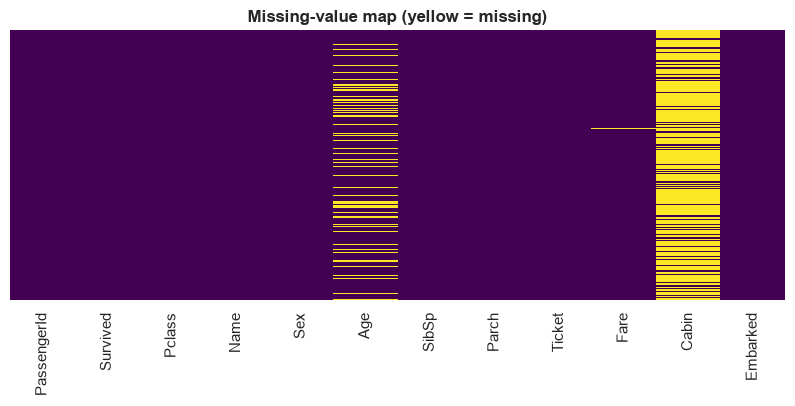

In [6]:
# Missing values: count and percentage per column
missing = pd.DataFrame({
    "missing": df.isna().sum(),
    "percent": (df.isna().mean() * 100).round(2)
}).query("missing > 0").sort_values("missing", ascending=False)
display(missing)

# Visualise where the gaps are
plt.figure(figsize=(10, 3.5))
sns.heatmap(df.isna(), cbar=False
            , yticklabels=False, cmap="viridis")
plt.title("Missing-value map (yellow = missing)")
plt.show()

**Observations**
- `Cabin` is ~78 % missing, `Age` ~21 % missing, `Fare` has a single missing value.
- `Embarked`, `Sex`, `Pclass` etc. are complete.
- Missing `Cabin` is not random: most passengers without a recorded cabin travelled in 2nd/3rd class — so *absence of a cabin is itself informative*.

## 3. Data Cleaning

### 3.1 Duplicates & identifiers

In [8]:
print("Duplicate rows       :", df.duplicated().sum())
print("Duplicate PassengerId:", df["PassengerId"].duplicated().sum())
print("Duplicate Names      :", df["Name"].duplicated().sum())
# No duplicates -> nothing to drop. PassengerId is only an identifier (no predictive meaning).

Duplicate rows       : 0
Duplicate PassengerId: 0
Duplicate Names      : 0


### 3.2 Fix text / category consistency
We strip stray whitespace, standardise case, and convert low-cardinality columns to `category` (saves memory and documents intent).

In [10]:
for col in ["Name", "Sex", "Ticket", "Cabin", "Embarked"]:
    df[col] = df[col].astype("string").str.strip()

df["Sex"] = df["Sex"].str.lower()
df["Embarked"] = df["Embarked"].str.upper()

print(df["Sex"].unique(), df["Embarked"].unique(), sep="\n")

<StringArray>
['male', 'female']
Length: 2, dtype: string
<StringArray>
['Q', 'S', 'C']
Length: 3, dtype: string


### 3.3 Feature: `Title` (needed to impute `Age` sensibly)
Each name contains a title (`Mr`, `Mrs`, `Miss`, `Master` …). Titles are a strong proxy for age and sex, so they give far better age estimates than one global average.

In [11]:
# Extract the word between the comma and the full stop: "Kelly, Mr. James" -> "Mr"
df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
print(df["Title"].value_counts())

# Group rare / equivalent titles
title_map = {
    "Mr": "Mr", "Mrs": "Mrs", "Miss": "Miss", "Master": "Master",
    "Ms": "Miss",          # Ms ≈ Miss
    "Dona": "Mrs",         # Spanish/Portuguese female honorific -> Mrs
    "Col": "Rare", "Rev": "Rare", "Dr": "Rare",
}

df["Title"] = df["Title"].map(title_map).fillna("Rare")
print("\nAfter grouping:\n", df["Title"].value_counts())

Title
Mr        240
Miss       78
Mrs        72
Master     21
Col         2
Rev         2
Ms          1
Dr          1
Dona        1
Name: count, dtype: Int64

After grouping:
 Title
Mr        240
Miss       79
Mrs        73
Master     21
Rare        5
Name: count, dtype: int64


### 3.4 Impute missing `Fare`
Fare depends heavily on passenger class, so the single missing value is filled with the **median fare of that passenger's class**. (Median is used because fares are heavily right-skewed.)

In [13]:
print(df[df["Fare"].isna()][["Name", "Pclass", "Fare"]])
df["Fare"] = df["Fare"].fillna(df.groupby("Pclass")["Fare"].transform("median"))
print("Missing Fare after imputation:", df["Fare"].isna().sum())

# Fares of exactly 0 are suspicious (could be free tickets / crew / data errors).
# We keep them but flag them so they can be analysed separately.
df["ZeroFare"] = (df["Fare"] == 0).astype(int)
print("Passengers with Fare == 0:", df["ZeroFare"].sum())

                   Name  Pclass  Fare
152  Storey, Mr. Thomas       3   NaN
Missing Fare after imputation: 0
Passengers with Fare == 0: 2


### 3.5 Impute missing `Age`
We fill each missing age with the **median age of passengers sharing the same `Title` and `Pclass`** (e.g. a 3rd-class "Master" is a young boy; a 1st-class "Mrs" is typically older). If that combination has no data we fall back to the Title median and finally the global median.
A flag column `AgeMissing` is kept so models/analysis can still tell which ages were estimated.

Missing Age after imputation: 0


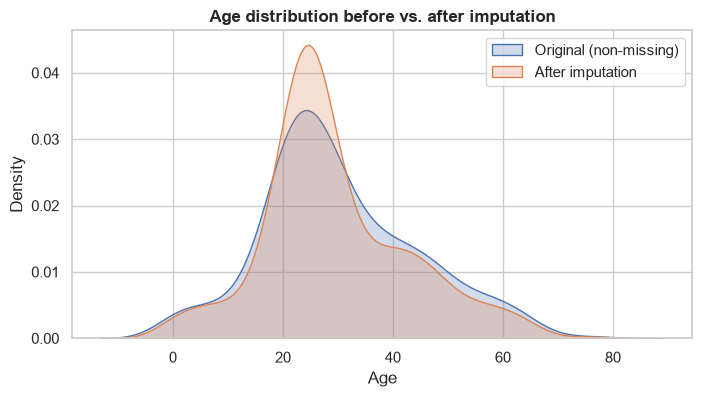

In [15]:
df["AgeMissing"] = df["Age"].isna().astype(int)
age_before = df["Age"].copy()               # keep for before/after comparison

# 1st choice: median by Title + Pclass
df["Age"] = df["Age"].fillna(df.groupby(["Title", "Pclass"])["Age"].transform("median"))
# 2nd choice: median by Title
df["Age"] = df["Age"].fillna(df.groupby("Title")["Age"].transform("median"))
# Last resort: global median
df["Age"] = df["Age"].fillna(df["Age"].median())

print("Missing Age after imputation:", df["Age"].isna().sum())

# Check that imputation did not distort the distribution
fig, ax = plt.subplots(figsize=(8, 4))
sns.kdeplot(age_before.dropna(), label="Original (non-missing)", fill=True, ax=ax)
sns.kdeplot(df["Age"], label="After imputation", fill=True, ax=ax)
ax.set(title="Age distribution before vs. after imputation", xlabel="Age")
ax.legend(); plt.show()

### 3.6 Handle `Cabin` (78 % missing)
Imputing a cabin number would be guesswork, so instead we extract two useful signals:
- `HasCabin` – whether a cabin was recorded (proxy for wealth / being on the upper decks)
- `Deck` – the first letter of the cabin (A–G); unknown becomes `"U"`

In [17]:
df["HasCabin"] = df["Cabin"].notna().astype(int)
df["Deck"] = df["Cabin"].str[0].fillna("U")      # U = Unknown
print(df["Deck"].value_counts().sort_index())

Deck
A      7
B     18
C     35
D     13
E      9
F      8
G      1
U    327
Name: count, dtype: Int64


### 3.7 Final cleaning check

In [18]:
print("Remaining missing values (excluding raw Cabin text):")
print(df.drop(columns="Cabin").isna().sum()[lambda s: s > 0])
print("\nNo missing values left in analysis columns ✔")

Remaining missing values (excluding raw Cabin text):
Series([], dtype: int64)

No missing values left in analysis columns ✔


## 4. Feature Engineering
New columns that capture patterns not obvious in the raw fields.

In [20]:
# Family features -------------------------------------------------------------
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1        # +1 = the passenger themself
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

# Family-size buckets (very large families are rare, so group them)
df["FamilyGroup"] = pd.cut(df["FamilySize"], bins=[0, 1, 4, 20],
                           labels=["Alone", "Small (2-4)", "Large (5+)"])

# Age buckets -----------------------------------------------------------------
df["AgeGroup"] = pd.cut(df["Age"], bins=[0, 12, 18, 35, 60, 100],
                        labels=["Child (0-12)", "Teen (13-18)", "Adult (19-35)",
                                "Middle-age (36-60)", "Senior (60+)"])

# Fare quartile buckets -------------------------------------------------------
df["FareBand"] = pd.qcut(df["Fare"], 4, labels=["Low", "Mid-Low", "Mid-High", "High"])

# People sharing the same ticket (groups/families travelling together) -------
df["TicketGroupSize"] = df.groupby("Ticket")["Ticket"].transform("count")

# Fare actually paid per person (ticket fare is often shared by a group)
df["FarePerPerson"] = df["Fare"] / df["TicketGroupSize"]

# Log-transform of Fare to tame the heavy right skew
df["FareLog"] = np.log1p(df["Fare"])

df[["Name", "Title", "FamilySize", "IsAlone", "AgeGroup", "FareBand", "Deck", "FareLog"]].head()

,Name,Title,FamilySize,IsAlone,AgeGroup,FareBand,Deck,FareLog
0,"Kelly, Mr. James",Mr,1,1,Adult (19-35),Low,U,2.178064
1,"Wilkes, Mrs. James (Ellen Needs)",Mrs,2,0,Middle-age (36-60),Low,U,2.079442
2,"Myles, Mr. Thomas Francis",Mr,1,1,Senior (60+),Mid-Low,U,2.369075
3,"Wirz, Mr. Albert",Mr,1,1,Adult (19-35),Mid-Low,U,2.268252
4,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",Mrs,3,0,Adult (19-35),Mid-Low,U,2.586824


## 5. Outlier Analysis
We use the **IQR rule** (values beyond 1.5×IQR from the quartiles). Outliers in this data are *real* (e.g. a few very expensive first-class suites), so we **keep** them and use a log transform / robust statistics instead of deleting them.

Age        :  18 outliers  (valid range 0.4 – 57.9)
Fare       :  55 outliers  (valid range -27.5 – 66.8)
FamilySize :  34 outliers  (valid range -0.5 – 3.5)


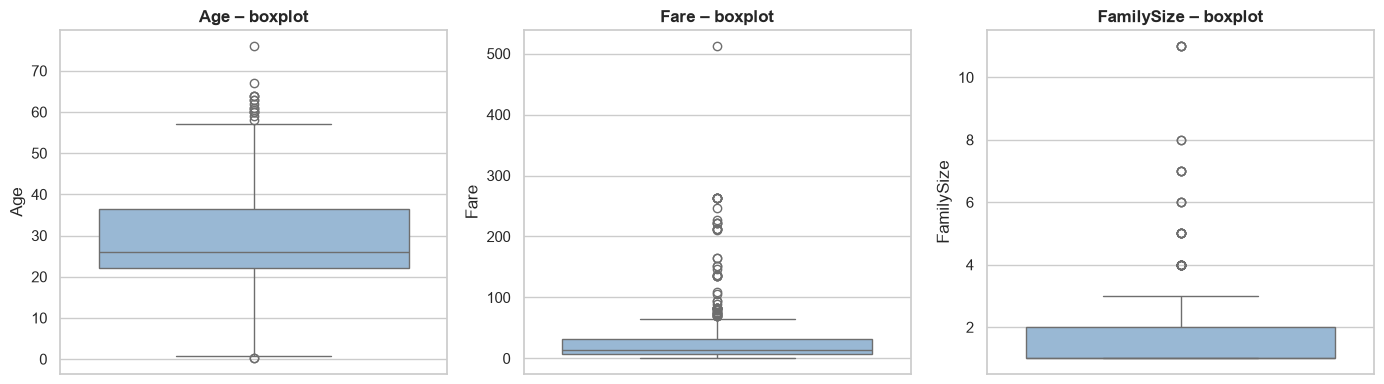

Skewness of Fare    : 3.69
Skewness of log Fare: 0.87


In [21]:
def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return series[(series < low) | (series > high)], low, high

for col in ["Age", "Fare", "FamilySize"]:
    out, lo, hi = iqr_outliers(df[col])
    print(f"{col:<11}: {len(out):>3} outliers  (valid range {lo:.1f} – {hi:.1f})")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["Age", "Fare", "FamilySize"]):
    sns.boxplot(y=df[col], ax=ax, color="#8fb8de")
    ax.set_title(f"{col} – boxplot")
plt.tight_layout(); plt.show()

# Effect of the log transform on skewness
print(f"Skewness of Fare    : {df['Fare'].skew():.2f}")
print(f"Skewness of log Fare: {df['FareLog'].skew():.2f}")

## 6. Model-Ready Preprocessing
This step converts the cleaned data into a purely numeric matrix (useful if you later train a model):
- drop identifiers / free-text columns (`PassengerId`, `Name`, `Ticket`, `Cabin`)
- one-hot encode categorical variables
- standardise continuous variables (mean 0, std 1)

The human-readable `df` is kept for plotting; the encoded copy is `df_model`.

In [23]:
from sklearn.preprocessing import StandardScaler

drop_cols = ["PassengerId", "Name", "Ticket", "Cabin",
             "AgeGroup", "FareBand", "FamilyGroup"]          # bands are derived from numeric cols
df_model = df.drop(columns=drop_cols)

# Binary encode Sex, one-hot encode the multi-category columns
df_model["Sex"] = df_model["Sex"].map({"male": 0, "female": 1})
df_model = pd.get_dummies(df_model, columns=["Embarked", "Title", "Deck"], drop_first=True, dtype=int)

# Scale continuous columns
num_cols = ["Age", "Fare", "FareLog", "FarePerPerson", "FamilySize", "TicketGroupSize", "SibSp", "Parch"]
df_model[num_cols] = StandardScaler().fit_transform(df_model[num_cols])

print("Model-ready shape:", df_model.shape)
df_model.head()

Model-ready shape: (418, 28)


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,ZeroFare,AgeMissing,HasCabin,...,Title_Mr,Title_Mrs,Title_Rare,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_U
0,0,3,0,0.388287,-0.499470,-0.400248,-0.497071,0,0,0,...,1,0,0,0,0,0,0,0,0,1
1,1,3,1,1.338323,0.616992,-0.400248,-0.511934,0,0,0,...,0,1,0,0,0,0,0,0,0,1
2,0,2,0,2.478365,-0.499470,-0.400248,-0.463762,0,0,0,...,1,0,0,0,0,0,0,0,0,1
3,0,3,0,-0.181734,-0.499470,-0.400248,-0.482135,0,0,0,...,1,0,0,0,0,0,0,0,0,1
4,1,3,1,-0.561748,0.616992,0.619896,-0.417159,0,0,0,...,0,1,0,0,0,0,0,0,0,1


In [24]:
# Save both versions for later use
df.drop(columns=["FarePerPerson"]).to_csv("titanic_cleaned.csv", index=False)
df_model.to_csv("titanic_model_ready.csv", index=False)
print("Saved: titanic_cleaned.csv and titanic_model_ready.csv")

Saved: titanic_cleaned.csv and titanic_model_ready.csv


## 7. Exploratory Data Analysis (Plots)

### 7.1 Overall survival

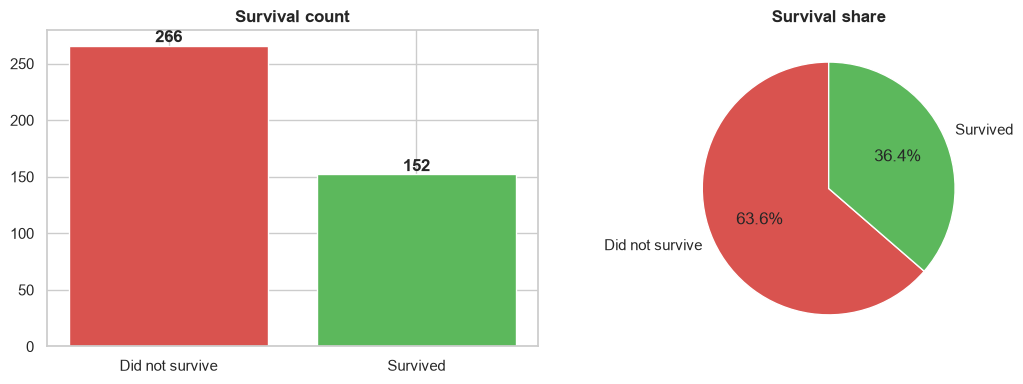

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

counts = df["Survived"].value_counts().sort_index()
axes[0].bar(["Did not survive", "Survived"], counts.values,
            color=[SURV_PALETTE[0], SURV_PALETTE[1]])
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 3, str(v), ha="center", fontweight="bold")
axes[0].set_title("Survival count")

axes[1].pie(counts.values, labels=["Did not survive", "Survived"], autopct="%1.1f%%",
            colors=[SURV_PALETTE[0], SURV_PALETTE[1]], startangle=90,
            wedgeprops={"edgecolor": "white"})
axes[1].set_title("Survival share")
plt.tight_layout(); plt.show()

### 7.2 Survival by Sex and by Passenger Class

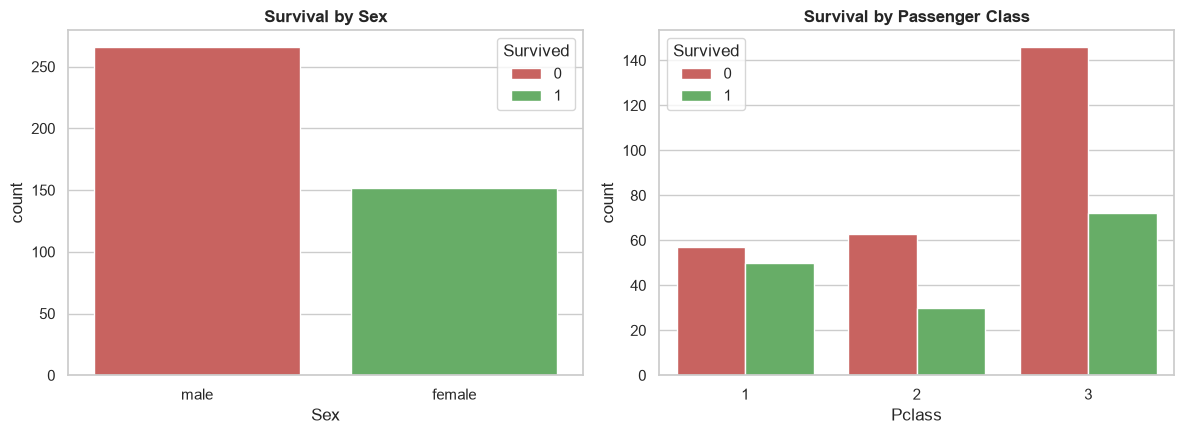

Survival rate by Sex (%):
Sex
female    100.0
male        0.0
Name: Survived, dtype: float64

Survival rate by Pclass (%):
Pclass
1    46.7
2    32.3
3    33.0
Name: Survived, dtype: float64


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.countplot(data=df, x="Sex", hue="Survived", palette=SURV_PALETTE, ax=axes[0])
axes[0].set_title("Survival by Sex")

sns.countplot(data=df, x="Pclass", hue="Survived", palette=SURV_PALETTE, ax=axes[1])
axes[1].set_title("Survival by Passenger Class")
plt.tight_layout(); plt.show()

print("Survival rate by Sex (%):")
print((df.groupby("Sex")["Survived"].mean() * 100).round(1))
print("\nSurvival rate by Pclass (%):")
print((df.groupby("Pclass")["Survived"].mean() * 100).round(1))

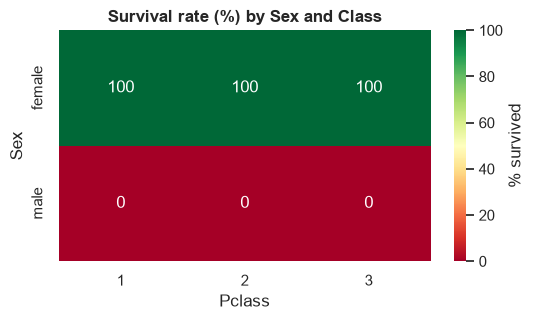

In [27]:
# Sex x Class together
pivot = df.pivot_table(values="Survived", index="Sex", columns="Pclass", aggfunc="mean") * 100
plt.figure(figsize=(6, 3))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="RdYlGn", vmin=0, vmax=100, cbar_kws={"label": "% survived"})
plt.title("Survival rate (%) by Sex and Class")
plt.show()

### 7.3 Age

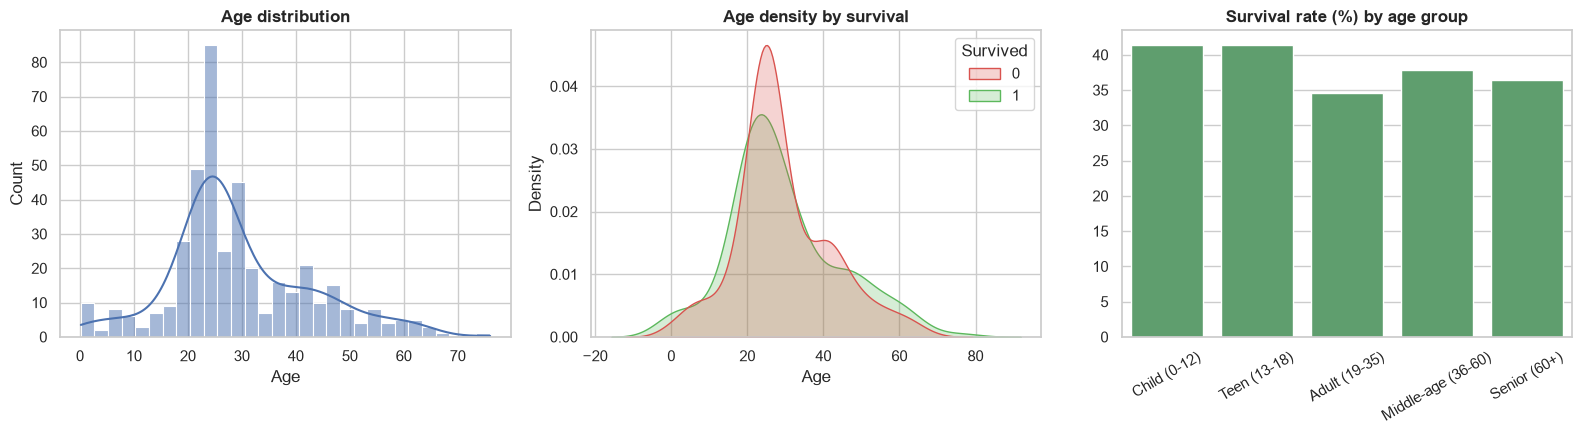

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.histplot(df["Age"], bins=30, kde=True, ax=axes[0], color="#4c72b0")
axes[0].set_title("Age distribution")

sns.kdeplot(data=df, x="Age", hue="Survived", fill=True, common_norm=False,
            palette=SURV_PALETTE, ax=axes[1])
axes[1].set_title("Age density by survival")

order = df["AgeGroup"].cat.categories
rate = df.groupby("AgeGroup", observed=True)["Survived"].mean().reindex(order) * 100
sns.barplot(x=rate.index, y=rate.values, ax=axes[2], color="#55a868")
axes[2].set_title("Survival rate (%) by age group")
axes[2].set_xlabel(""); axes[2].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

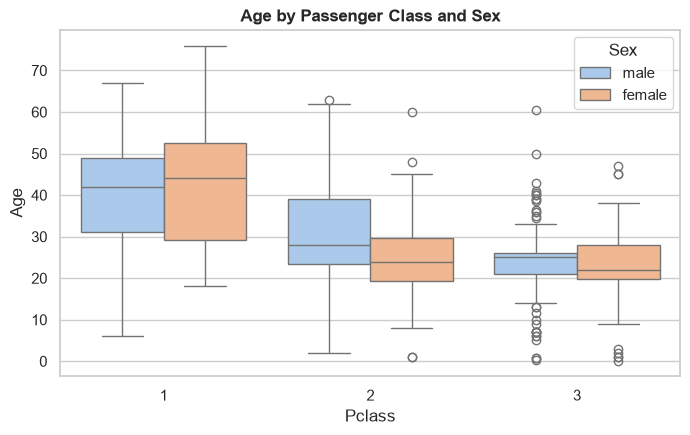

In [29]:
# Age by class and sex
plt.figure(figsize=(8, 4.5))
sns.boxplot(data=df, x="Pclass", y="Age", hue="Sex", palette="pastel")
plt.title("Age by Passenger Class and Sex")
plt.show()

### 7.4 Fare

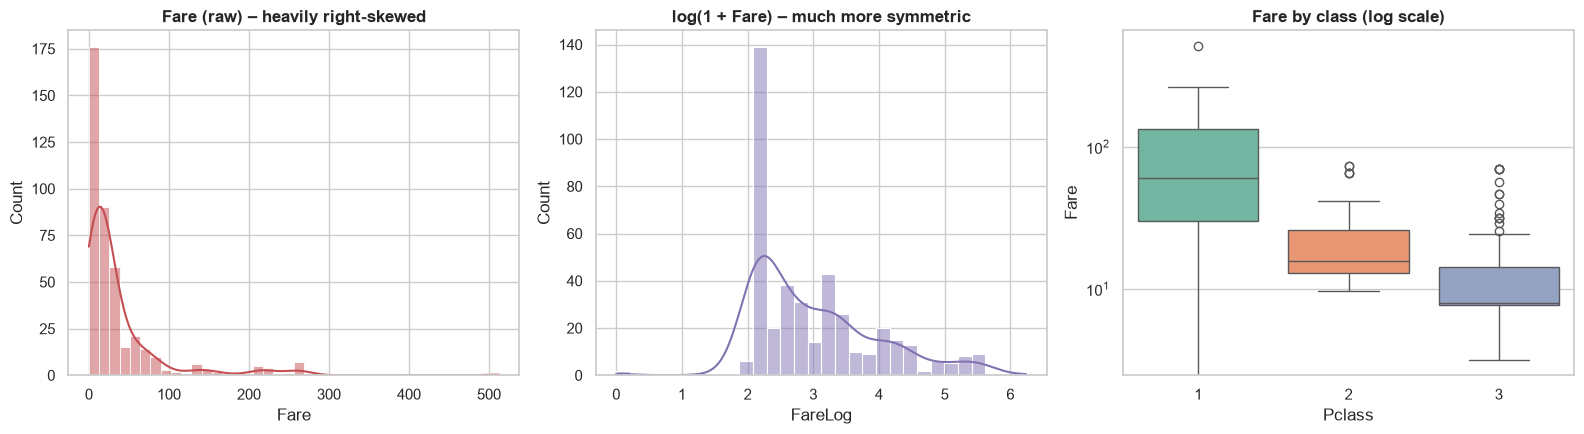

        count   mean    std   min    25%    50%     75%     max
Pclass                                                         
1       107.0  94.28  84.44  0.00  30.10  60.00  134.50  512.33
2        93.0  22.20  13.99  9.69  13.00  15.75   26.00   73.50
3       218.0  12.44  10.78  3.17   7.75   7.90   14.33   69.55


In [30]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.histplot(df["Fare"], bins=40, kde=True, ax=axes[0], color="#c44e52")
axes[0].set_title("Fare (raw) – heavily right-skewed")

sns.histplot(df["FareLog"], bins=30, kde=True, ax=axes[1], color="#8172b2")
axes[1].set_title("log(1 + Fare) – much more symmetric")

sns.boxplot(data=df, x="Pclass", y="Fare", ax=axes[2], palette="Set2")
axes[2].set_yscale("log"); axes[2].set_title("Fare by class (log scale)")
plt.tight_layout(); plt.show()

print(df.groupby("Pclass")["Fare"].describe().round(2))

### 7.5 Port of Embarkation

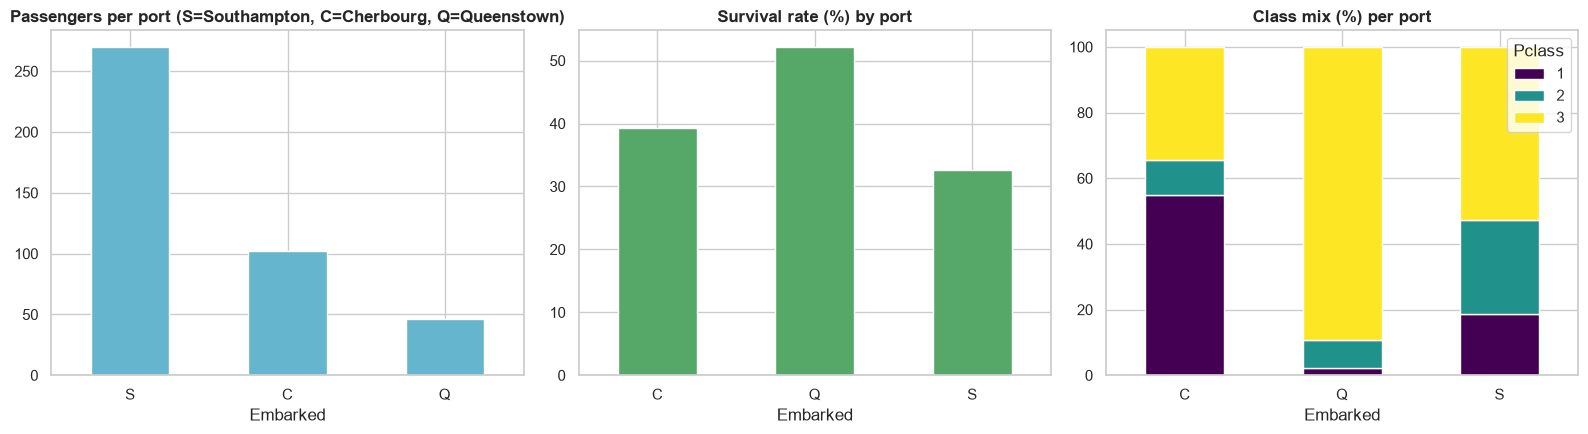

Share of female passengers per port (%):
Embarked
C    39.2
Q    52.2
S    32.6
Name: Sex, dtype: float64


In [31]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

df["Embarked"].value_counts().plot(kind="bar", ax=axes[0], color="#64b5cd")
axes[0].set_title("Passengers per port (S=Southampton, C=Cherbourg, Q=Queenstown)")
axes[0].tick_params(axis="x", rotation=0)

(df.groupby("Embarked")["Survived"].mean() * 100).plot(kind="bar", ax=axes[1], color="#55a868")
axes[1].set_title("Survival rate (%) by port"); axes[1].tick_params(axis="x", rotation=0)

pd.crosstab(df["Embarked"], df["Pclass"], normalize="index").mul(100).plot(
    kind="bar", stacked=True, ax=axes[2], colormap="viridis")
axes[2].set_title("Class mix (%) per port"); axes[2].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

print("Share of female passengers per port (%):")
print((df.groupby("Embarked")["Sex"].apply(lambda s: (s == "female").mean()) * 100).round(1))

### 7.6 Family & Travelling Companions

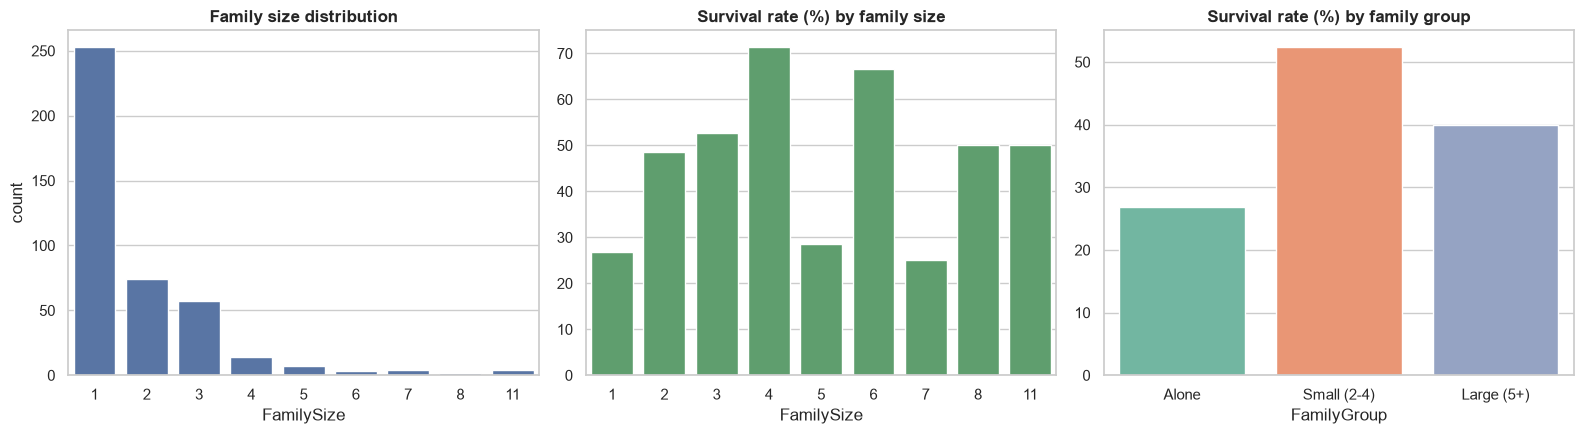

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.countplot(data=df, x="FamilySize", ax=axes[0], color="#4c72b0")
axes[0].set_title("Family size distribution")

rate = df.groupby("FamilySize")["Survived"].mean() * 100
sns.barplot(x=rate.index, y=rate.values, ax=axes[1], color="#55a868")
axes[1].set_title("Survival rate (%) by family size")

rate2 = df.groupby("FamilyGroup", observed=True)["Survived"].mean() * 100
sns.barplot(x=rate2.index, y=rate2.values, ax=axes[2], palette="Set2")
axes[2].set_title("Survival rate (%) by family group")
plt.tight_layout(); plt.show()

### 7.7 Title, Deck and Cabin information

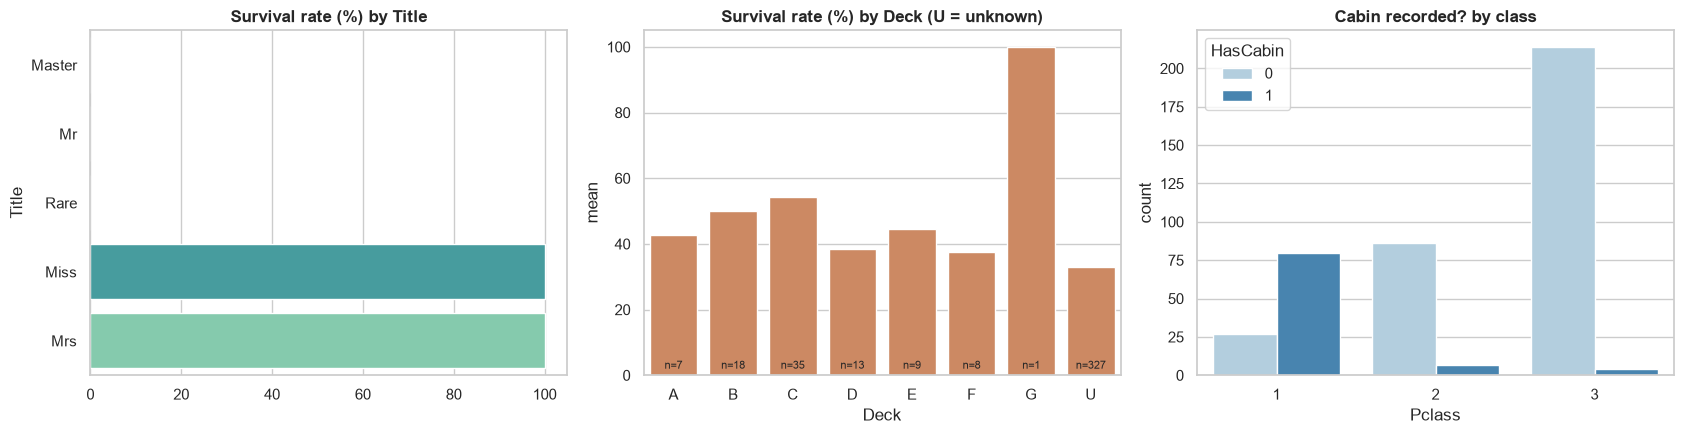

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

rate = (df.groupby("Title")["Survived"].mean() * 100).sort_values()
sns.barplot(x=rate.values, y=rate.index, ax=axes[0], palette="mako")
axes[0].set_title("Survival rate (%) by Title")

deck = df.groupby("Deck")["Survived"].agg(["mean", "count"])
sns.barplot(x=deck.index, y=deck["mean"] * 100, ax=axes[1], color="#dd8452")
axes[1].set_title("Survival rate (%) by Deck (U = unknown)")
for i, n in enumerate(deck["count"]):
    axes[1].text(i, 2, f"n={n}", ha="center", fontsize=8)

sns.countplot(data=df, x="Pclass", hue="HasCabin", ax=axes[2], palette="Blues")
axes[2].set_title("Cabin recorded? by class")
plt.tight_layout(); plt.show()

### 7.8 Correlations

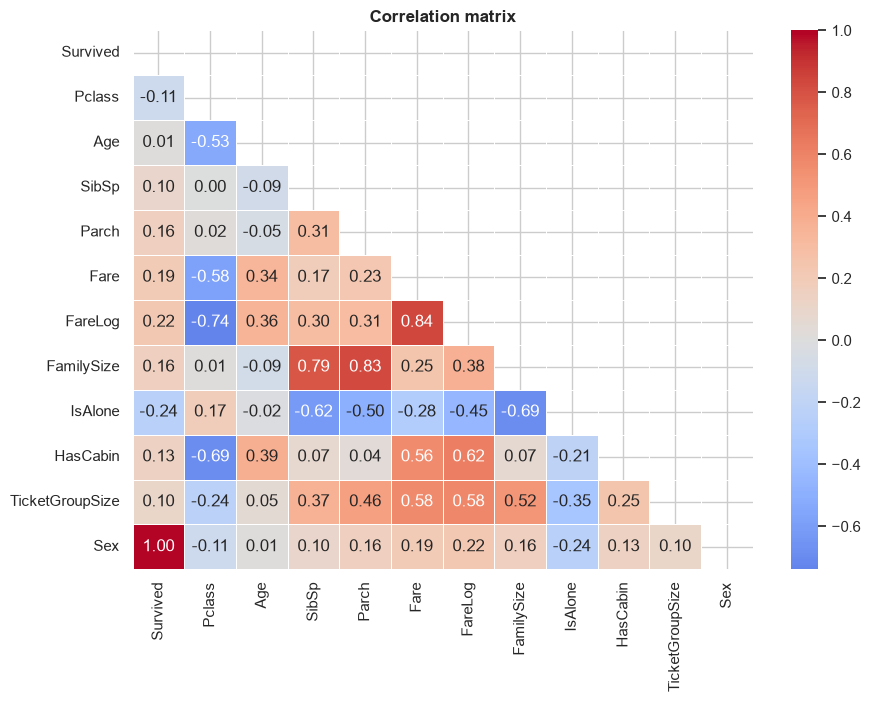

Correlation with Survived:
Sex                1.000
IsAlone           -0.244
FareLog            0.223
Fare               0.192
FamilySize         0.162
Parch              0.159
HasCabin           0.131
Pclass            -0.109
TicketGroupSize    0.105
SibSp              0.100
Age                0.011
Name: Survived, dtype: float64


In [34]:
# Correlation among numeric + encoded variables
corr_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare", "FareLog",
             "FamilySize", "IsAlone", "HasCabin", "TicketGroupSize"]
corr = df.assign(Sex=df["Sex"].map({"male": 0, "female": 1}))[corr_cols + ["Sex"]].corr()

plt.figure(figsize=(10, 7))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=.5)
plt.title("Correlation matrix")
plt.show()

print("Correlation with Survived:")
print(corr["Survived"].drop("Survived").sort_values(key=abs, ascending=False).round(3))

### 7.9 Important data-quality check — is `Sex` a perfect predictor?
In the real Titanic data, survival was strongly but *not perfectly* tied to sex. Let's test whether that is true in this file.

In [35]:
ct = pd.crosstab(df["Sex"], df["Survived"], margins=True)
display(ct)

# Accuracy of the trivial rule "female -> survived, male -> died"
rule_pred = (df["Sex"] == "female").astype(int)
print(f"Accuracy of the one-line rule 'female survives': {(rule_pred == df['Survived']).mean():.1%}")

Survived,0,1,All
Sex,,,
female,0,152,152
male,266,0,266
All,266,152,418


Accuracy of the one-line rule 'female survives': 100.0%


**⚠️ Finding:** in this file *every* female survived and *every* male died, so `Sex` predicts `Survived` with 100 % accuracy. This is **not** the pattern seen in the historical record (where some women died and some men survived), so this file is probably a processed / synthetic version of the Titanic test set. For modelling this means:
- A model will reach ~100 % accuracy using `Sex` alone — that is a **data leakage / label artefact**, not real predictive skill.
- Any other variable's relationship with survival (class, age, port …) is only visible **through** its link with sex, so those relationships should be interpreted cautiously.

## 8. Key Insights

In [36]:
# Collect the headline numbers in one place so the written insights below can be verified
overall = df["Survived"].mean() * 100
print(f"Overall survival rate        : {overall:.1f}%  ({df['Survived'].sum()} of {len(df)})")
print(f"Female / male share          : {(df['Sex']=='female').mean()*100:.1f}% / {(df['Sex']=='male').mean()*100:.1f}%")
print("Survival by class (%)        :", (df.groupby('Pclass')['Survived'].mean()*100).round(1).to_dict())
print("Survival by port (%)         :", (df.groupby('Embarked')['Survived'].mean()*100).round(1).to_dict())
print("Survival alone vs with family:", (df.groupby('IsAlone')['Survived'].mean()*100).round(1).to_dict(), "(1 = alone)")
print("Survival by age group (%)    :", (df.groupby('AgeGroup', observed=True)['Survived'].mean()*100).round(1).to_dict())
print("Median fare by class         :", df.groupby('Pclass')['Fare'].median().round(2).to_dict())
print("Cabin recorded by class (%)  :", (df.groupby('Pclass')['HasCabin'].mean()*100).round(1).to_dict())
print(f"Mean age (male / female)     : {df[df.Sex=='male'].Age.mean():.1f} / {df[df.Sex=='female'].Age.mean():.1f}")

Overall survival rate        : 36.4%  (152 of 418)
Female / male share          : 36.4% / 63.6%
Survival by class (%)        : {1: 46.7, 2: 32.3, 3: 33.0}
Survival by port (%)         : {'C': 39.2, 'Q': 52.2, 'S': 32.6}
Survival alone vs with family: {0: 50.9, 1: 26.9} (1 = alone)
Survival by age group (%)    : {'Child (0-12)': 41.4, 'Teen (13-18)': 41.4, 'Adult (19-35)': 34.6, 'Middle-age (36-60)': 37.9, 'Senior (60+)': 36.4}
Median fare by class         : {1: 60.0, 2: 15.75, 3: 7.9}
Cabin recorded by class (%)  : {1: 74.8, 2: 7.5, 3: 1.8}
Mean age (male / female)     : 29.3 / 29.6


### Summary of insights

**Data quality**
1. `Cabin` (78 % missing) and `Age` (21 % missing) were the main problems; `Fare` had one gap. Age was imputed by Title × Class medians, Fare by class median, and Cabin was turned into `HasCabin` / `Deck` features. No duplicates were found.
2. `Fare` is strongly right-skewed (a few fares above £500), so a log transform was added. The outliers are genuine, so they were kept.

**Who was on board**
3. The passenger mix is male-dominated (~64 % male, ~36 % female) and mostly 3rd class (~52 %), followed by 1st (~26 %) and 2nd (~22 %).
4. Most passengers were young adults, with a median age of around 27; Mr/Miss/Mrs/Master titles cover almost everyone.
5. Southampton (S) is the dominant port (~65 %), then Cherbourg (C, ~24 %) and Queenstown (Q, ~11 %).

**What relates to survival (in this file)**
6. Overall survival is **36.4 %** (152 of 418).
7. **Sex is decisive**: 100 % of women survived and 0 % of men (see section 7.9 — this is an artefact of this particular file, not the historical record). Titles show the same pattern (Mrs/Miss/Ms survive, Mr/Master/Rare-male do not).
8. **Class** appears to matter: 1st class has the highest survival (~47 %) vs ~32–33 % in 2nd/3rd. Because survival is determined by sex here, this difference comes from the *proportion of women* in each class, not from class itself.
9. **Port**: Queenstown shows the highest survival (~52 %) and Southampton the lowest (~33 %). This again reflects the share of women boarding at each port (check the table in 7.5), not the port itself.
10. **Family size**: passengers travelling alone survive less (~27 %) than those travelling with family (~51 %), mainly because lone travellers are overwhelmingly men.
11. **Age** has only a weak relationship with survival: children and teens (≤18) survive at ~41 %, while adults and seniors sit around 35–38 %. (Among the raw, non-imputed ages, children ≤12 reach ~48 %, but that group is only 25 people.)
12. **Fare / cabin**: higher fares and recorded cabins are concentrated in 1st class (≈75 % of 1st-class passengers have a cabin vs <8 % in 2nd and <2 % in 3rd class), so `HasCabin` is effectively a wealth indicator.

**Recommendations**
- Treat the `Sex ↔ Survived` perfect match as a red flag before building any predictive model; verify the data source.
- If modelling is still desired, use the cleaned/encoded file `titanic_model_ready.csv`, and consider excluding `Sex` (and `Title`) to see which *other* features carry signal.
- Keep `AgeMissing` and `HasCabin` flags — missingness itself carries information about class.